# 📊 Step 5: Exploratory Data Analysis & Statistical Hypothesis Testing (`05_eda.ipynb`)

### Overview of Exploratory Analysis & Statistical Tests
1. **Basic Data Inspection:** `head()`, `shape`, `describe()`, `value_counts()`.
2. **Distribution & Skewness Check:** `mean` vs `median` check (`mean > median` = Right Skewed) + `sns.histplot(..., kde=True)` and `sns.kdeplot()`.
3. **Outlier Detection & Log Transformation:** `sns.boxplot()` before and after `np.log10()`.
4. **Groupby & Pivot Table:** `df.groupby(["country"]).agg(...)` and `pd.pivot_table()`.
5. **Scatter Plot & Line Plot:** `sns.scatterplot()` and `sns.lineplot(..., marker="o")`.
6. **Correlation Heatmap:** `df.corr()` + `sns.heatmap(..., cmap="coolwarm", fmt=".2f", annot=True)`.
7. **Statistical Hypothesis Testing:**
   - **T-Test (`ttest_ind`)**: Continuous vs Continuous (Tsunami `mag` vs Non-Tsunami `mag`)
   - **ANOVA (`f_oneway`)**: Continuous vs Categorical (`mag` across `alert` levels)
   - **Chi-Square (`chi2_contingency` with `pd.crosstab`)**: Categorical vs Categorical (`alert` vs `severity_flag`)

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, f_oneway, chi2_contingency

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

df = pd.read_csv("data/earthquakes_cleaned.csv")
print("Dataset Shape (rows, columns):", df.shape)
df.head()

Dataset Shape (rows, columns): (104464, 35)
                      time  latitude  ... depth_flag severity_flag
0  2021-01-31 23:20:49.923  -31.7493  ...    shallow      standard
1  2021-01-31 23:08:17.161  -15.4902  ...       deep      standard
2  2021-01-31 22:54:19.760   19.7529  ...    shallow      standard
3  2021-01-31 22:06:00.832   28.1524  ...    shallow      standard
4  2021-01-31 21:51:14.016   71.3212  ...    shallow      standard

[5 rows x 35 columns]


### 5.1 Summary Statistics (`describe`) & Category Counts (`value_counts`)

In [2]:
numeric_cols = ["mag", "depth_km", "sig", "nst", "gap", "rms", "dmin", "magError", "depthError"]
print("Summary Statistics:")
print(df[numeric_cols].describe())

print("\nDepth Flag Value Counts:")
print(df["depth_flag"].value_counts())

print("\nSeverity Flag Value Counts:")
print(df["severity_flag"].value_counts())

print("\nAlert Level Value Counts:")
print(df["alert"].value_counts())

Summary Statistics:
                 mag       depth_km  ...       magError     depthError
count  104464.000000  104464.000000  ...  104464.000000  104464.000000
mean        4.260216      72.050379  ...       0.118949       4.703364
std         0.607566     123.625494  ...       0.061093       5.395354
min         3.000000      -3.740000  ...       0.000000       0.000000
25%         4.000000      10.000000  ...       0.078704       1.890000
50%         4.300000      21.100000  ...       0.110000       2.011000
75%         4.600000      71.302500  ...       0.149000       6.989000
max         8.800000     681.238000  ...       3.770000    1023.200000

[8 rows x 9 columns]

Depth Flag Value Counts:
depth_flag
shallow    78018
deep       26446
Name: count, dtype: int64

Severity Flag Value Counts:
severity_flag
standard       103789
destructive       675
Name: count, dtype: int64

Alert Level Value Counts:
alert
unassessed    100209
green           4085
yellow           124
red          

### 5.2 Distribution & Skewness Check (`Mean` vs `Median`, `histplot`, `kdeplot`)
- **Right Skewed (`mean > median`)**: High-value outliers pull the mean to the right.
- **Left Skewed (`mean < median`)**: Low-value outliers pull the mean to the left.

--- Skewness Check (Mean vs Median) ---
mag        -> Mean:     4.26 | Median:     4.30 -> Left/Normal (mean <= median)
depth_km   -> Mean:    72.05 | Median:    21.10 -> Right Skewed (mean > median)
nst        -> Mean:    41.74 | Median:    32.00 -> Right Skewed (mean > median)
gap        -> Mean:   121.52 | Median:   112.00 -> Right Skewed (mean > median)
dmin       -> Mean:     3.15 | Median:     1.81 -> Right Skewed (mean > median)
sig        -> Mean:   288.01 | Median:   285.00 -> Right Skewed (mean > median)


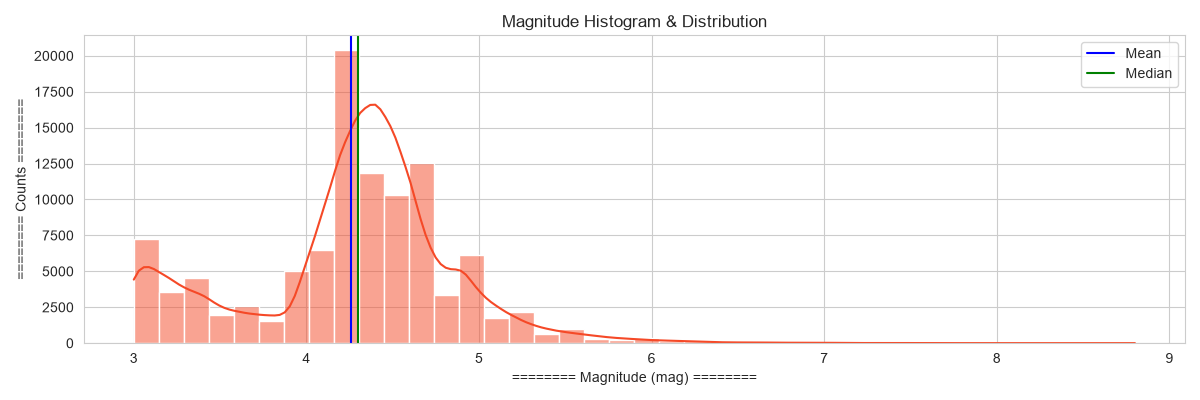

In [3]:
print("--- Skewness Check (Mean vs Median) ---")
for col in ["mag", "depth_km", "nst", "gap", "dmin", "sig"]:
    mean_val = df[col].mean()
    median_val = df[col].median()
    skew_type = "Right Skewed (mean > median)" if mean_val > median_val else "Left/Normal (mean <= median)"
    print(f"{col:10s} -> Mean: {mean_val:8.2f} | Median: {median_val:8.2f} -> {skew_type}")

plt.figure(figsize=(12, 4))
sns.histplot(data=df, x="mag", color="#F54927", kde=True, bins=40)
plt.axvline(x=df["mag"].mean(), color="blue", linestyle="--", label=f"Mean ({df['mag'].mean():.2f})")
plt.axvline(x=df["mag"].median(), color="green", linestyle="-", label=f"Median ({df['mag'].median():.2f})")
plt.title("Histogram & KDE of Earthquake Magnitude (mag)")
plt.xlabel("======== Magnitude (mag) ========")
plt.ylabel("======== Counts ========")
plt.legend()
plt.show()

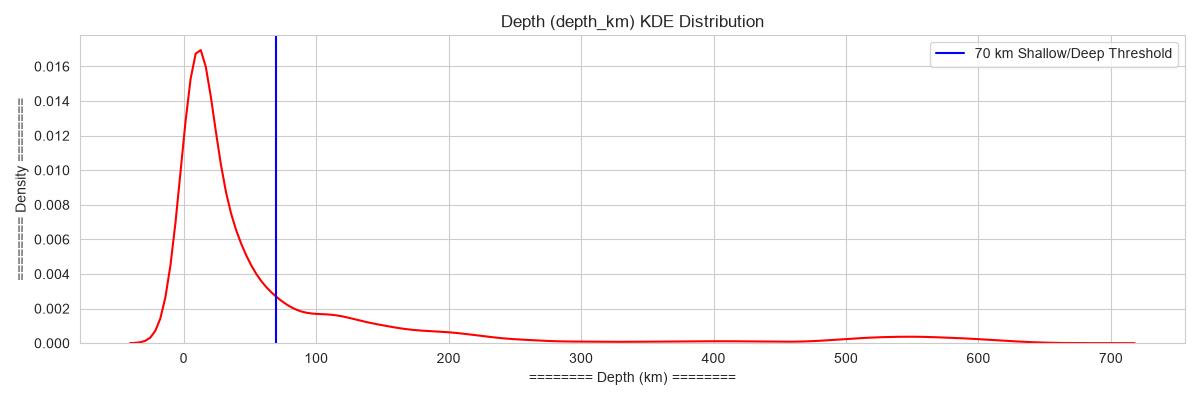

In [4]:
plt.figure(figsize=(12, 4))
sns.kdeplot(data=df, x="depth_km", color="r")
plt.axvline(x=df["depth_km"].mean(), color="blue", linestyle="--", label=f"Mean ({df['depth_km'].mean():.2f} km)")
plt.axvline(x=df["depth_km"].median(), color="green", linestyle="-", label=f"Median ({df['depth_km'].median():.2f} km)")
plt.title("KDE Plot of Earthquake Depth (Right Skewed: Mean > Median)")
plt.xlabel("Depth (km)")
plt.ylabel("Density")
plt.legend()
plt.show()

### 5.3 Outlier Detection (`sns.boxplot`) & Log Transformation (`np.log10`)
I use `sns.boxplot()` to detect outliers and `np.log10()` to compress extreme right-skewed values.

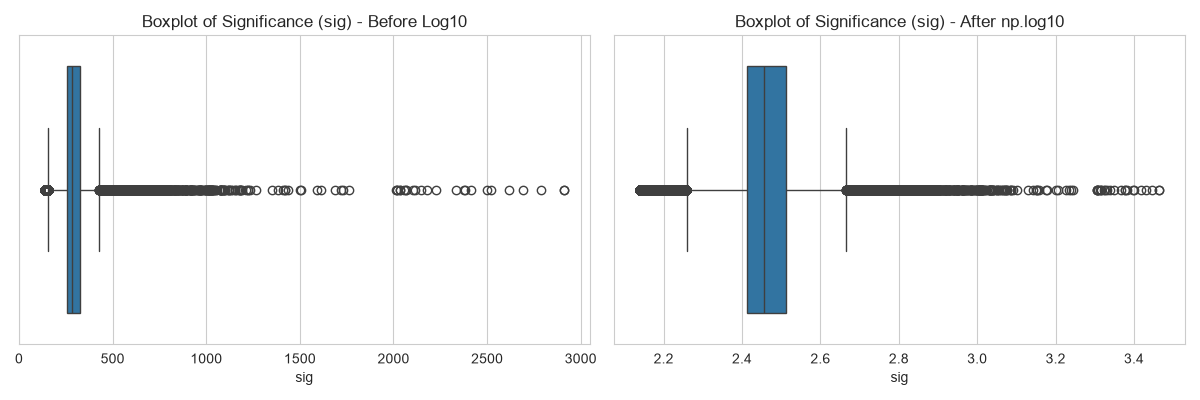

In [5]:
fig, axe = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=df["nst"], ax=axe[0], color="#F54927")
axe[0].set_title("Boxplot of Station Count (nst) — Raw (With Outliers)")

nst_log10 = np.log10(df["nst"] + 1)
sns.boxplot(x=nst_log10, ax=axe[1], color="g")
axe[1].set_title("Boxplot of Station Count — After np.log10(nst + 1)")

plt.tight_layout()
plt.show()

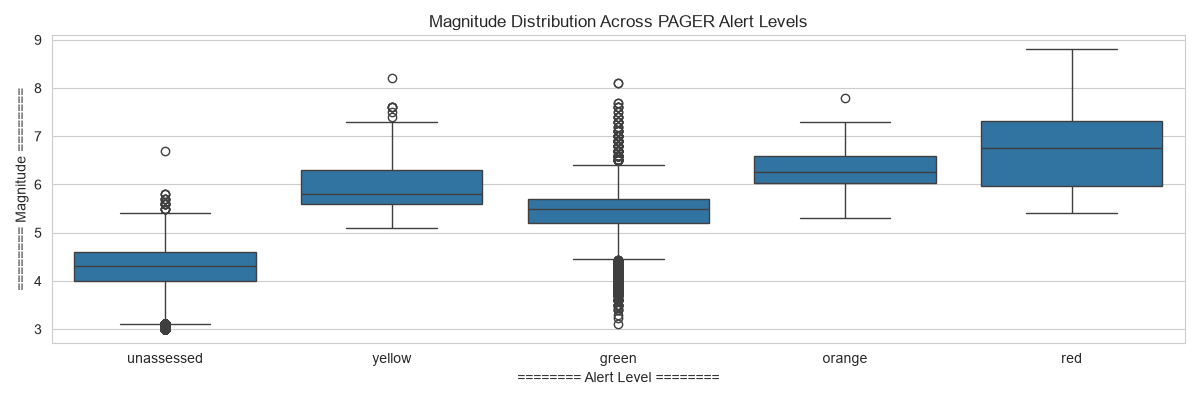

In [6]:
plt.figure(figsize=(12, 4))
sns.boxplot(
    data=df[df["alert"] != "unassessed"],
    x="alert",
    y="mag",
    order=["green", "yellow", "orange", "red"],
)
plt.title("Earthquake Magnitude Distribution Across Alert Levels")
plt.xlabel("Alert Level")
plt.ylabel("Magnitude (mag)")
plt.show()

### 5.4 GroupBy Aggregations (`.agg()`) & Pivot Tables (`pd.pivot_table`)

In [7]:
country_summary = (
    df.groupby(["country"])
    .agg({"sig": "sum", "mag": "mean", "id": "count"})
    .reset_index()
    .rename(columns={"id": "earthquake_count"})
    .sort_values("earthquake_count", ascending=False)
)
print("Top 10 Countries by Earthquake Count:")
print(country_summary.head(10))

pivot_depth_year = pd.pivot_table(
    df,
    values="id",
    index="depth_flag",
    columns="Year",
    aggfunc="count",
)
print("\nPivot Table — Shallow vs Deep Earthquakes per Year:")
print(pivot_depth_year)

Top 10 Countries by Earthquake Count:
                    country      sig       mag  earthquake_count
16                   Alaska  2368680  3.466963             12425
148               Indonesia  2456398  4.494554              7840
158                   Japan  1980912  4.499332              6292
290                  Russia  1779904  4.482370              5712
280             Philippines  1404859  4.557136              4351
274        Papua New Guinea  1094056  4.556373              3397
285             Puerto Rico   546910  3.340523              3152
325  South Sandwich Islands  1025345  4.679028              3025
354                   Tonga   939371  4.578844              2890
77                    Chile   849115  4.363281              2865

Pivot Table — Shallow vs Deep Earthquakes per Year:
Year         2021   2022   2023   2024   2025
depth_flag                                   
deep         5027   5287   5590   5334   5208
shallow     16899  14921  15240  13325  17633


### 5.5 Bivariate & Time-Series Plots (`sns.scatterplot` & `sns.lineplot`)

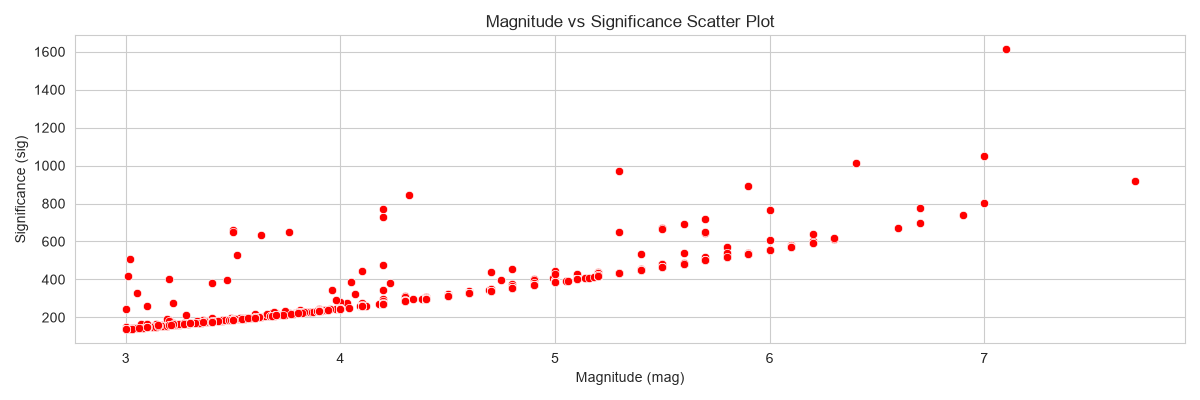

In [8]:
plt.figure(figsize=(12, 4))
sns.scatterplot(data=df, x="mag", y="sig", color="r")
plt.xlabel("Magnitude (mag)")
plt.ylabel("Significance Score (sig)")
plt.title("Magnitude vs Significance Scatter Plot")
plt.show()

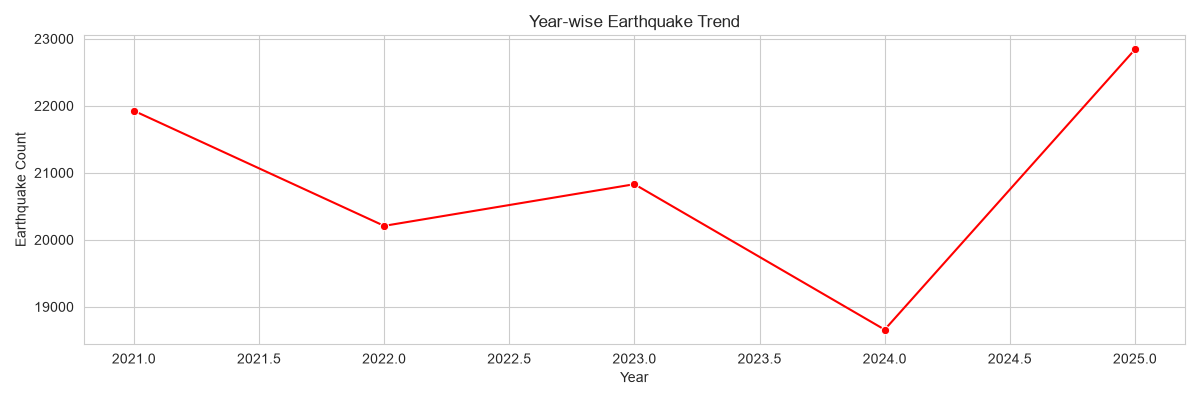

In [9]:
yearly_counts = df.groupby(["Year"])[["id"]].count().reset_index().rename(columns={"id": "count"})

plt.figure(figsize=(12, 4))
sns.lineplot(data=yearly_counts, x="Year", y="count", color="r", marker="o")
plt.xlabel("Year")
plt.ylabel("Earthquake Count")
plt.title("Year-wise Earthquake Trend")
plt.show()

### 5.6 Correlation Matrix (`df.corr()`) & Heatmap (`sns.heatmap`)

Correlation Matrix:
             mag  depth_km   sig   nst   gap   rms  dmin  magError  depthError
mag         1.00      0.05  0.89  0.42 -0.50  0.36  0.28     -0.21       -0.11
depth_km    0.05      1.00  0.01  0.03 -0.13  0.03  0.00     -0.04        0.30
sig         0.89      0.01  1.00  0.46 -0.47  0.27  0.21     -0.21       -0.12
nst         0.42      0.03  0.46  1.00 -0.38  0.06 -0.02     -0.37       -0.11
gap        -0.50     -0.13 -0.47 -0.38  1.00 -0.22 -0.12      0.14        0.22
rms         0.36      0.03  0.27  0.06 -0.22  1.00  0.06     -0.08       -0.05
dmin        0.28      0.00  0.21 -0.02 -0.12  0.06  1.00     -0.01       -0.10
magError   -0.21     -0.04 -0.21 -0.37  0.14 -0.08 -0.01      1.00        0.02
depthError -0.11      0.30 -0.12 -0.11  0.22 -0.05 -0.10      0.02        1.00


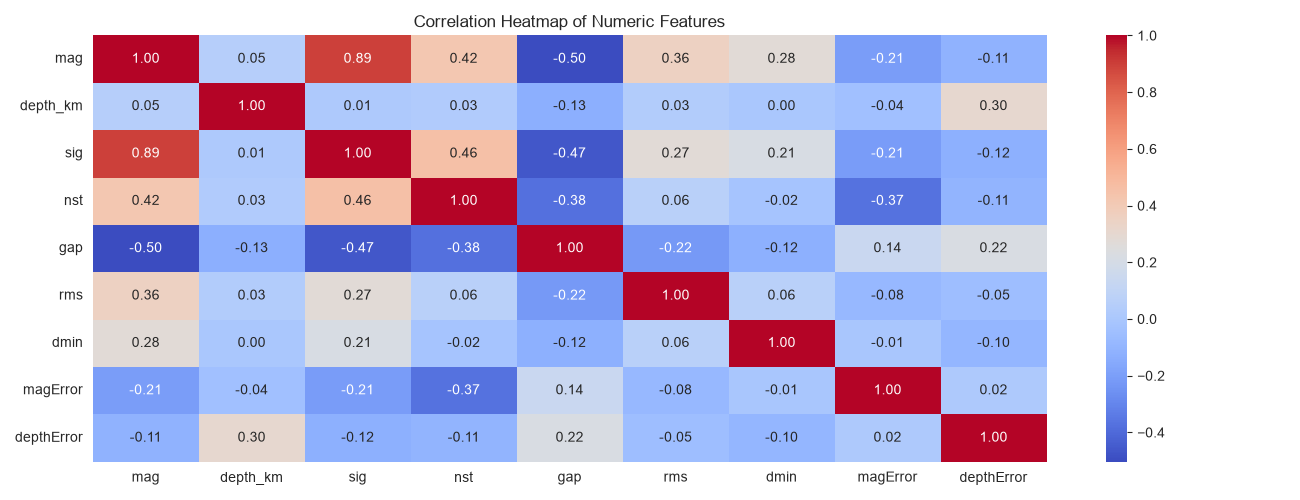

In [10]:
corr_data = df[numeric_cols].corr()
print("Correlation Matrix:")
print(round(corr_data, 2))

plt.figure(figsize=(13, 5))
sns.heatmap(corr_data, cmap="coolwarm", fmt=".2f", annot=True)
plt.title("Correlation Heatmap of Numeric Features")
plt.show()

### 5.7 Statistical Hypothesis Testing (`ttest_ind`, `f_oneway`, `chi2_contingency`)
Hypothesis test setup:
- **Null Hypothesis ($H_0$):** There is no significant difference / relationship.
- **Alternate Hypothesis ($H_1$):** There is a significant difference / relationship.
- **Decision Rule:** If `p_val < 0.05` $\implies$ **Reject Null Hypothesis ($H_0$)**.

In [11]:
# 1. T-Test (ttest_ind): Magnitude of Tsunami vs Non-Tsunami Earthquakes
tsunami_mag = df[df["tsunami"] == 1]["mag"]
no_tsunami_mag = df[df["tsunami"] == 0]["mag"]
s_ttest, p_val_ttest = ttest_ind(tsunami_mag, no_tsunami_mag)
print("1. T-Test (Magnitude of Tsunami vs Non-Tsunami Earthquakes):")
print("   p_val =", p_val_ttest)
print("   p_val < 0.05 ->", p_val_ttest < 0.05, "(Reject Null Hypothesis: Significant difference)")

# 2. ANOVA (f_oneway): Magnitude across Alert Levels (green, yellow, orange, red)
green = df[df["alert"] == "green"]["mag"]
yellow = df[df["alert"] == "yellow"]["mag"]
orange = df[df["alert"] == "orange"]["mag"]
red = df[df["alert"] == "red"]["mag"]
s_anova, p_val_anova = f_oneway(green, yellow, orange, red)
print("\n2. ANOVA Test (Magnitude across Alert Levels: green, yellow, orange, red):")
print("   p_val =", p_val_anova)
print("   p_val < 0.05 ->", p_val_anova < 0.05, "(Reject Null Hypothesis: Significant difference)")

# 3. Chi-Square Test (chi2_contingency): pd.crosstab between alert and severity_flag
cross = pd.crosstab(df["alert"], df["severity_flag"])
print("\n3. Chi-Square Test (pd.crosstab between alert and severity_flag):")
print(cross)
chi2_stat, p_val_chi2, dof, expected = chi2_contingency(cross)
print("   p_val =", p_val_chi2)
print("   p_val < 0.05 ->", p_val_chi2 < 0.05, "(Reject Null Hypothesis: Significant relationship)")

1. T-Test (Magnitude of Tsunami vs Non-Tsunami Earthquakes):
   p_val = 0.0
   p_val < 0.05 -> True (Reject Null Hypothesis: Significant difference)

2. ANOVA Test (Magnitude across Alert Levels: green, yellow, orange, red):
   p_val = 3.5131227397316176e-46
   p_val < 0.05 -> True (Reject Null Hypothesis: Significant difference)

3. Chi-Square Test (pd.crosstab between alert and severity_flag):
severity_flag  destructive  standard
alert                               
green                  586      3499
orange                  17         5
red                     18         6
unassessed               1    100208
yellow                  53        71
   p_val = 0.0
   p_val < 0.05 -> True (Reject Null Hypothesis: Significant relationship)
